In [1]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import textwrap

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [2]:
csv_files = glob.glob('strategy_one_results/results_*.csv')

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")

df.columns

Combined dataframe shape: (391, 13)


Index(['id', 'timestamp', 'model', 'pair', 'option_1', 'option_2',
       'selected_choice', 'response_text', 'infection_rate_selected',
       'npi_level_selected', 'infection_rate_non_selected',
       'npi_level_non_selected', 'temperature'],
      dtype='object')

In [3]:
# Create is_bad_choice column
df['is_bad_choice'] = (
    (df['infection_rate_selected'] > df['infection_rate_non_selected']) & 
    (df['npi_level_selected'] >= df['npi_level_non_selected'])
)

df['is_bad_choice'].value_counts()

is_bad_choice
False    317
True      74
Name: count, dtype: int64

In [4]:
df['infection_preference'] = (df['infection_rate_selected'] - df['infection_rate_non_selected'])
df['npi_preference'] = (df['npi_level_selected'] - df['npi_level_non_selected'])

In [5]:
def generate_boxplots(response_col, df=df, context_cols=None, use_percentage=False):
    # Set high DPI for Jupyter notebook
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 150

    sns.set_theme(style='whitegrid')

    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line

    if context_cols is None:
        context_cols = ['model']

    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''
    
    # Calculate overall mean for reference line
    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100

    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))

    # Create separate plot for each context
    for col in context_cols:
        grouped = df.groupby(col)[response_col]
        
        # Prepare data for boxplot
        data_to_plot = []
        labels = []
        
        for name, group in grouped:
            if len(group) > 0:
                if use_percentage:
                    data_to_plot.append(group.values * 100)
                else:
                    data_to_plot.append(group.values)
                labels.append(wrap_label(str(name)))
        
        # Adjust figure height based on number of items
        fig_height = max(4, len(labels) * 0.5)
        fig, ax = plt.subplots(figsize=(10, fig_height))
        
        # Create horizontal boxplot
        bp = ax.boxplot(data_to_plot, 
                        vert=False,  # Horizontal orientation
                        patch_artist=True,  # Enable face color customization
                        medianprops={'color': 'black', 'linewidth': 2},
                        boxprops={'facecolor': '#d62728', 'edgecolor': 'black', 'linewidth': 1.5},
                        whiskerprops={'color': 'black', 'linewidth': 1.5},
                        capprops={'color': 'black', 'linewidth': 1.5},
                        flierprops={'marker': 'o', 'markerfacecolor': 'gray', 
                                   'markersize': 6, 'markeredgecolor': 'black', 'alpha': 0.5})
        
        # Vertical mean line
        ax.axvline(overall_mean, color='black', linestyle='--', linewidth=2, alpha=0.7,
                   label=f'Overall mean = {overall_mean:.2f}{unit}')
        
        # Labels with wrapping
        ax.set_yticklabels(labels, fontsize=13)
        
        xlabel = f'{response_col} (Distribution with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Distribution)'
        
        ax.set_xlabel(xlabel, fontsize=14, fontweight='bold')
        ax.set_title(f'{response_col} by {col}', fontsize=16, fontweight='bold', pad=15)
        ax.grid(True, axis='x', alpha=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=11, loc='best')
        
        # Increase tick label size
        ax.tick_params(axis='x', labelsize=12)
        
        plt.tight_layout()
        plt.show()

    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")


# Example usage:
# For raw values (like infection_rate_selected):
# generate_bradley_terry_model('infection_rate_selected', df=df)

# For percentage values (like is_bad_choice which is 0/1):
# generate_bradley_terry_model('is_bad_choice', df=df, use_percentage=True)


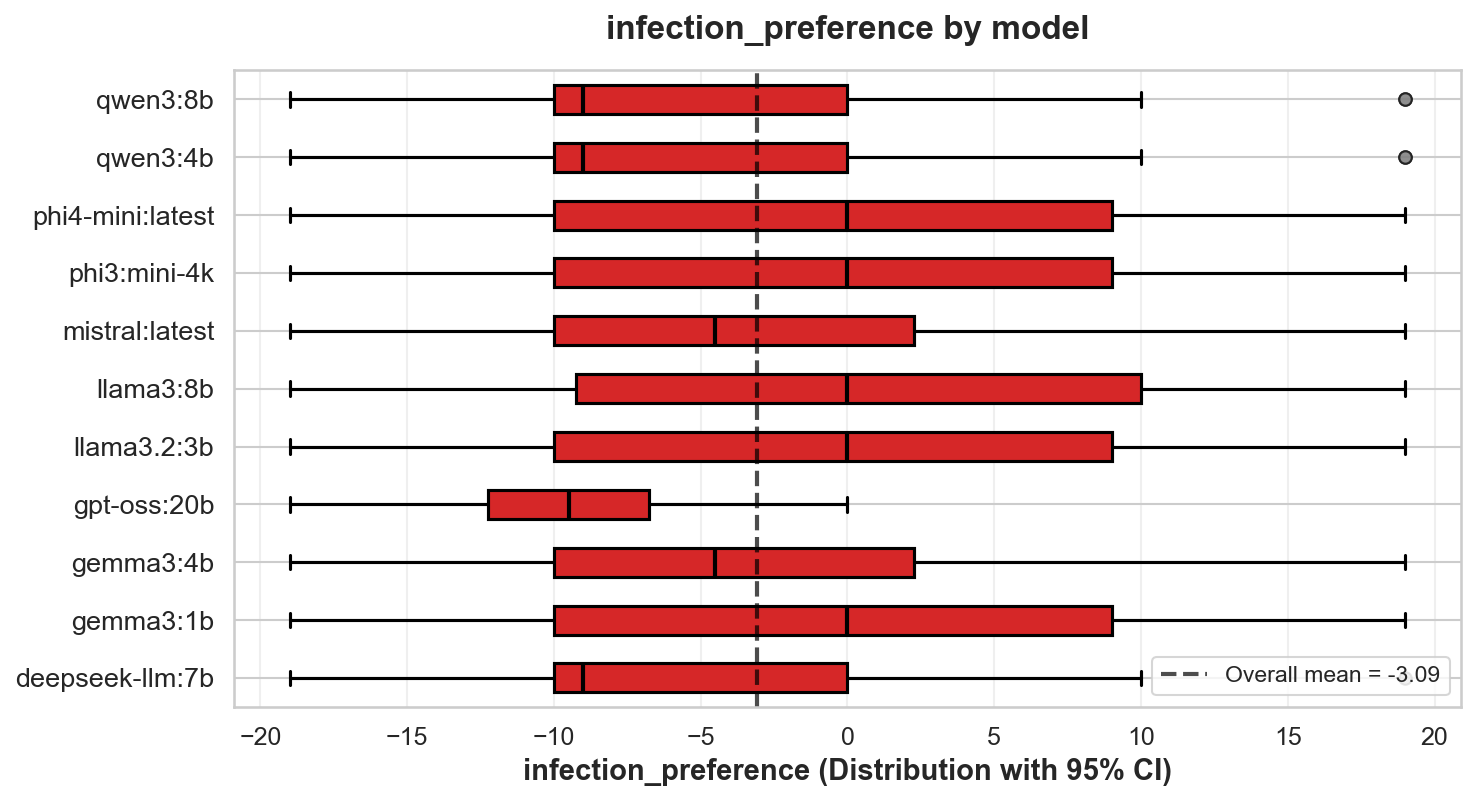


Labels wrapped at 30 characters per line
Overall mean infection_preference: -3.09


In [6]:
generate_boxplots('infection_preference', df=df, context_cols=['model'], use_percentage=False)

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_bad_choice_by_group(df, group_col, figsize=(10, 6)):
    """
    Simple bar plot showing proportion of bad choices by a single grouping variable.
    
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'demographic')
    """
    # Calculate proportions
    bad_choice_rate = df.groupby(group_col)['is_bad_choice'].mean().reset_index()
    bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
    
    plt.figure(figsize=figsize)
    sns.barplot(data=bad_choice_rate, x=group_col, y='bad_choice_pct', 
                palette='viridis')
    plt.ylabel('Bad Choice Rate (%)')
    plt.xlabel(group_col.replace('_', ' ').title())
    plt.title(f'Strategy One: Bad Choice Frequency by {group_col.replace("_", " ").title()}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

/var/folders/30/tv8y9sjj267fr2h48qhlgsh00000gn/T/ipykernel_86185/1744703379.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bad_choice_rate, x=group_col, y='bad_choice_pct',


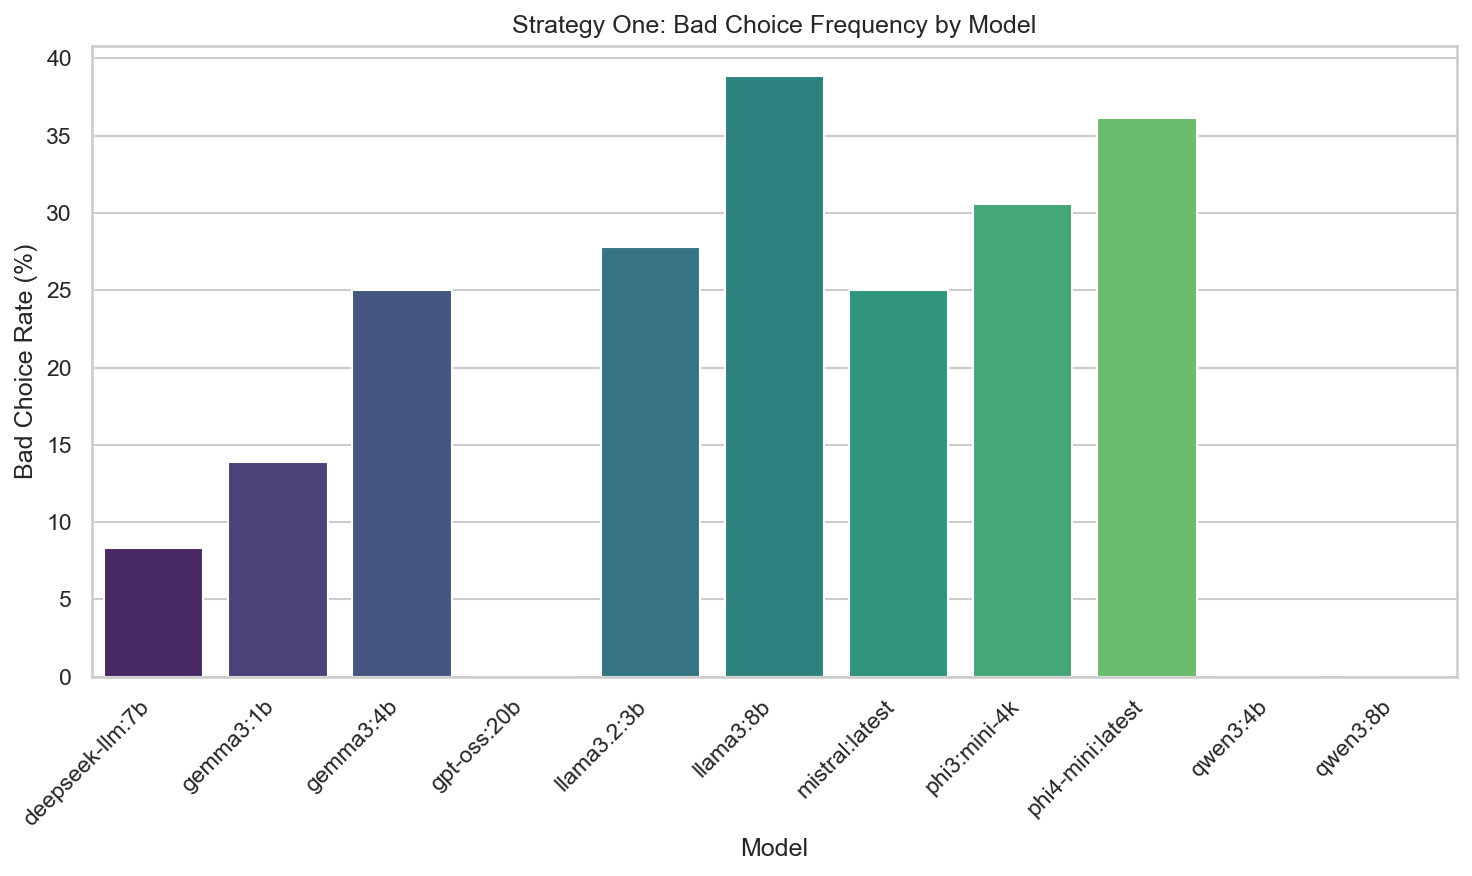

In [17]:
# Example 1: Compare bad choice rates across models
plot_bad_choice_by_group(df, 'model')


In [9]:
df.groupby('model')['is_bad_choice'].value_counts()

model             is_bad_choice
deepseek-llm:7b   False            33
                  True              3
gemma3:1b         False            31
                  True              5
gemma3:4b         False            27
                  True              9
gpt-oss:20b       False            36
llama3.2:3b       False            26
                  True             10
llama3:8b         False            22
                  True             14
mistral:latest    False            27
                  True              9
phi3:mini-4k      False            25
                  True             11
phi4-mini:latest  False            23
                  True             13
qwen3:4b          False            35
qwen3:8b          False            32
Name: count, dtype: int64

In [ ]:
from statsmodels.stats.proportion import proportion_confint

def summarize_bad_choice(df, group_col, alpha=0.05, method="wilson"):
    g = df.groupby(group_col)['is_bad_choice']
    count = g.sum()
    nobs = g.size()
    p = count / nobs
    low, high = proportion_confint(count.values, nobs.values, alpha=alpha, method=method)
    out = pd.DataFrame({
        group_col: count.index,
        'count_bad': count.values,
        'n': nobs.values,
        'prop': p.values,
        'low': low,
        'high': high
    }).sort_values(group_col)
    out['prop_pct'] = 100*out['prop']
    out['err_low_pct'] = np.clip(100*(out['prop'] - out['low']), 0, None)
    out['err_high_pct'] = np.clip(100*(out['high'] - out['prop']), 0, None)
    return out

def rate_and_n_panels(df, group_col, figsize=(10,8)):
    summ = summarize_bad_choice(df, group_col)
    order = summ[group_col].tolist()
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True,
                             gridspec_kw={'height_ratios':[3,1]})
    # top: rate with CIs
    ax = axes[0]
    sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,
                palette='viridis', errorbar=None, ax=ax)
    centers = [p.get_x()+p.get_width()/2 for p in ax.patches]
    ax.errorbar(centers, summ['prop_pct'].values,
                yerr=[summ['err_low_pct'].values, summ['err_high_pct'].values],
                fmt='none', ecolor='black', elinewidth=1.1, capsize=4, capthick=1.1)
    ax.set_ylabel('Irrational Choice Rate (%)')
    ax.set_title(f'Strategy One: Irrational Choice Rate by {group_col.replace("_"," ").title()}')
    # bottom: counts
    ax2 = axes[1]
    sns.barplot(data=summ, x=group_col, y='n', order=order, color='lightgray', ax=ax2)
    ax2.set_ylabel('Responses (n)')
    ax2.set_xlabel(group_col.replace('_',' ').title())
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    return fig, axes


/var/folders/30/tv8y9sjj267fr2h48qhlgsh00000gn/T/ipykernel_86185/1996533748.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,


(<Figure size 1500x1200 with 2 Axes>,
 array([<Axes: title={'center': 'Bad Choice Rate with 95% CI by Model'}, xlabel='model', ylabel='Bad Choice Rate (%)'>,
        <Axes: xlabel='Model', ylabel='Responses (n)'>], dtype=object))

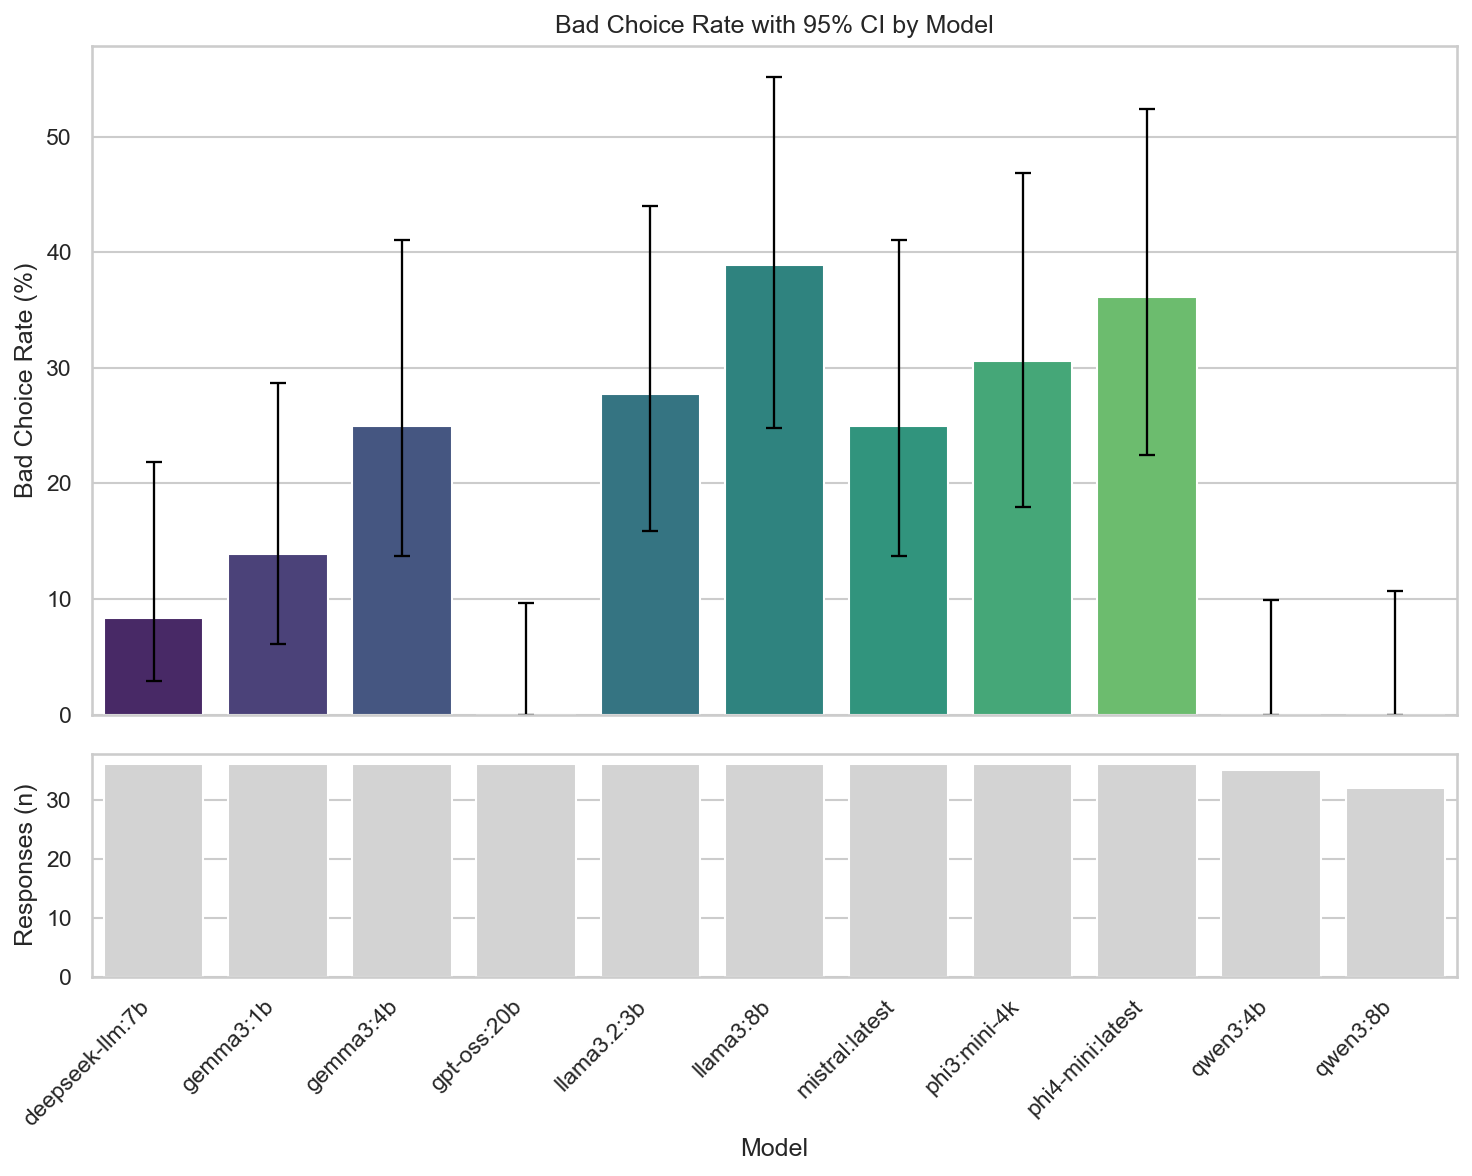

In [19]:
rate_and_n_panels(df, 'model')